In [1]:
import pandas as pd
from pipeline import IndicatorSpec, build_feature_df
from data import fetch_binance_klines
from simulation.rules import Rule, RuleGroup, ALL, ANY
from simulation.rule_features import add_last_n_compare, add_cross_compare
from simulation.simulator import Strategy, SimConfig, run_simulation, align_timeframes
from plot_simulation import plot_simulation
from plotter import plot_interactive, PlotConfig, IndicatorSpec
from mtf_plot import make_plot_indicators, assert_plot_columns_exist
from features.ema_spreads import EmaSpreadSpec, add_ema_spread_features
from features.cross_through import CrossThroughSpec, add_cross_through_features
from features.stochastic_signals import add_stochastic_signal_features
from features.ema_compression import EMACompressionSpec, add_ema_compression_features, range_slope_strong_for_n_tf_candles
from simulation.rules import Ctx
from analytics import (
    trades_to_frame,
    plot_balance_by_trade,
    plot_trade_pnl_bars,
    trade_summary_table
)
from plot_toggles import (
    PlotToggle,
    make_plot_indicators_from_toggles,
    assert_plot_columns_exist,
)

from ema_diagnostic_plots import (
    ema_pair_spread_panel,
    ema_group_spread_panel,
    ema_cut_through_panel,
)
from simulation.simulator import (
    TradeExitConfig,
    StopLossConfig,
    PositionSizingConfig,
    TakeProfitConfig,
)

In [2]:
symbol = "BTCUSDT"
market = "spot"
tz = "Asia/Karachi"

# Start earlier for EMA warmup.
fetch_start = "2025-01-01"
sim_start = "2026-05-06"
end = None

In [3]:
# ============================================================
# STOCHASTIC Configs
# ============================================================

STOCH_CFG = {
    "k_length": 14,
    "d_length": 3,
    "smooth": 3,
}

In [4]:
### 1 Minute Indicators ###
EMA20_1m = "1m__ema__EMA_20"
EMA50_1m = "1m__ema__EMA_50"
EMA100_1m = "1m__ema__EMA_100"
EMA150_1m = "1m__ema__EMA_150"
EMA200_1m = "1m__ema__EMA_200"
MACD_1M = "1m__macd_8_21_5__MACD"
MACD_SIGNAL_1M = "1m__macd_8_21_5__SIGNAL"
MACD_HIST_1M = "1m__macd_8_21_5__HIST"
BULL_DIV_1m = "1m__rsi14__BULL_DIV"
BEAR_DIV_1m = "1m__rsi14__BEAR_DIV"
BULL_START_RSI_1m = "1m__rsi14__BULL_START_RSI"
BEAR_START_RSI_1m = "1m__rsi14__BEAR_START_RSI"
STO_K_1M = "1m__st14__K"
STO_D_1M = "1m__st14__D"
STO_1M_UP20_ACTIVE_5 = "1m__st14__K_CROSS_UP_20_ACTIVE_5"
STO_1M_DOWN20_ACTIVE_5 = "1m__st14__K_CROSS_DOWN_20_ACTIVE_5"

### 5 Minute Indicators ###
EMA20_5m = "5m__ema__EMA_20"
EMA50_5m = "5m__ema__EMA_50"
EMA75_5m = "5m__ema__EMA_75"
EMA100_5m = "5m__ema__EMA_100"
EMA125_5m = "5m__ema__EMA_125"
EMA150_5m = "5m__ema__EMA_150"
EMA175_5m = "5m__ema__EMA_175"
EMA200_5m = "5m__ema__EMA_200"
MACD_5M = "5m__macd_8_21_5__MACD"
MACD_SIGNAL_5M = "5m__macd_8_21_5__SIGNAL"
MACD_HIST_5M = "5m__macd_8_21_5__HIST"
BULL_DIV_5m = "5m__rsi14__BULL_DIV"
BEAR_DIV_5m = "5m__rsi14__BEAR_DIV"
BULL_START_RSI_5m = "5m__rsi14__BULL_START_RSI"
BEAR_START_RSI_5m = "5m__rsi14__BEAR_START_RSI"
STO_K_5M = "5m__st14__K"
STO_D_5M = "5m__st14__D"
STO_5M_UP20_ACTIVE_3 = "5m__st14__K_CROSS_UP_20_ACTIVE_3"
STO_5M_DOWN20_ACTIVE_3 = "5m__st14__K_CROSS_DOWN_20_ACTIVE_3"


### 15 Minute Indicators ###
EMA20_15m = "15m__ema__EMA_20"
EMA50_15m = "15m__ema__EMA_50"
EMA75_15m = "15m__ema__EMA_75"
EMA100_15m = "15m__ema__EMA_100"
EMA125_15m = "15m__ema__EMA_125"
EMA150_15m = "15m__ema__EMA_150"
EMA175_15m = "15m__ema__EMA_175"
EMA200_15m = "15m__ema__EMA_200"
MACD_15M = "15m__macd_8_21_5__MACD"
MACD_SIGNAL_15M = "15m__macd_8_21_5__SIGNAL"
MACD_HIST_15M = "15m__macd_8_21_5__HIST"
BULL_DIV_15m = "15m__rsi14__BULL_DIV"
BEAR_DIV_15m = "15m__rsi14__BEAR_DIV"
BULL_START_RSI_15m = "15m__rsi14__BULL_START_RSI"
BEAR_START_RSI_15m = "15m__rsi14__BEAR_START_RSI"
STO_K_15M = "15m__st14__K"
STO_D_15M = "15m__st14__D"
STO_15M_UP20_ACTIVE_3 = "15m__st14__K_CROSS_UP_20_ACTIVE_3"
STO_15M_DOWN20_ACTIVE_3 = "15m__st14__K_CROSS_DOWN_20_ACTIVE_3"

### 1 Hour Indicators ###
EMA20_1h = "1h__ema__EMA_20"
EMA50_1h = "1h__ema__EMA_50"
EMA75_1h = "1h__ema__EMA_75"
EMA100_1h = "1h__ema__EMA_100"
EMA125_1h = "1h__ema__EMA_125"
EMA150_1h = "1h__ema__EMA_150"
EMA175_1h = "1h__ema__EMA_175"
EMA200_1h = "1h__ema__EMA_200"
MACD_1H = "1h__macd_8_21_5__MACD"
MACD_SIGNAL_1H = "1h__macd_8_21_5__SIGNAL"
MACD_HIST_1H = "1h__macd_8_21_5__HIST"
BULL_DIV_1h = "1h__rsi14__BULL_DIV"
BEAR_DIV_1h = "1h__rsi14__BEAR_DIV"
BULL_START_RSI_1h = "1h__rsi14__BULL_START_RSI"
BEAR_START_RSI_1h = "1h__rsi14__BEAR_START_RSI"
STO_K_1H = "1h__st14__K"
STO_D_1H = "1h__st14__D"
STO_1H_UP20_ACTIVE_3 = "1h__st14__K_CROSS_UP_20_ACTIVE_3"
STO_1H_DOWN20_ACTIVE_3 = "1h__st14__K_CROSS_DOWN_20_ACTIVE_3"

######################################################################

MS_1M_TAG = "ms_5_2"
MS_5M_TAG = "ms_4_2"
MS_15M_TAG = "ms_4_2"
MS_1H_TAG = "ms_3_2"

MS_HH_1M = f"1m__{MS_1M_TAG}__HH"
MS_HL_1M = f"1m__{MS_1M_TAG}__HL"
MS_LH_1M = f"1m__{MS_1M_TAG}__LH"
MS_LL_1M = f"1m__{MS_1M_TAG}__LL"

MS_HH_5M = f"5m__{MS_5M_TAG}__HH"
MS_HL_5M = f"5m__{MS_5M_TAG}__HL"
MS_LH_5M = f"5m__{MS_5M_TAG}__LH"
MS_LL_5M = f"5m__{MS_5M_TAG}__LL"

MS_HH_15M = f"15m__{MS_15M_TAG}__HH"
MS_HL_15M = f"15m__{MS_15M_TAG}__HL"
MS_LH_15M = f"15m__{MS_15M_TAG}__LH"
MS_LL_15M = f"15m__{MS_15M_TAG}__LL"

MS_LAST_LOW_1M = f"1m__{MS_1M_TAG}__LAST_SWING_LOW"
MS_LAST_HIGH_1M = f"1m__{MS_1M_TAG}__LAST_SWING_HIGH"

MS_LAST_LOW_5M = f"5m__{MS_5M_TAG}__LAST_SWING_LOW"
MS_LAST_HIGH_5M = f"5m__{MS_5M_TAG}__LAST_SWING_HIGH"

MS_LAST_LOW_15M = f"15m__{MS_15M_TAG}__LAST_SWING_LOW"
MS_LAST_HIGH_15M = f"15m__{MS_15M_TAG}__LAST_SWING_HIGH"

def flag_recent(c, col: str, lookback: int) -> bool:
    for i in range(int(lookback)):
        if c.flag(col, shift=-i):
            return True
    return False


def any_recent_structure(c, cols: list[str], lookback: int) -> bool:
    for col in cols:
        if flag_recent(c, col, lookback):
            return True
    return False

In [5]:
# ============================================================
# 1m indicators
# ============================================================

ind_1m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [20, 50, 100, 150, 200, 250],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),
    IndicatorSpec("market_structure", tag=MS_1M_TAG, config={
        "left": 5,
        "right": 2,
        "min_swing_pct": 0.03,
    }),
    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]


# ============================================================
# 5m indicators
# ============================================================

ind_5m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [20, 50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),
    IndicatorSpec("market_structure", tag=MS_5M_TAG, config={
        "left": 4,
        "right": 2,
        "min_swing_pct": 0.05,
    }),
    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]


# ============================================================
# 15m indicators
# ============================================================

ind_15m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [20, 50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),
    IndicatorSpec("market_structure", tag=MS_15M_TAG, config={
        "left": 4,
        "right": 2,
        "min_swing_pct": 0.08,
    }),
    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]

# ============================================================
# 1h indicators
# ============================================================

ind_1h = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [20, 50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),
    IndicatorSpec("market_structure", tag=MS_1H_TAG, config={
        "left": 3,
        "right": 2,
        "min_swing_pct": 0.10,
    }),
    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]

In [6]:
# 1m base data
df1 = fetch_binance_klines(
    symbol=symbol,
    interval="1m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df1_feat, _, _ = build_feature_df(
    raw_df=df1,
    tz=tz,
    ma_windows=[],
    indicators=ind_1m,
)


# 5m filter data
df5 = fetch_binance_klines(
    symbol=symbol,
    interval="5m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df5_feat, _, _ = build_feature_df(
    raw_df=df5,
    tz=tz,
    ma_windows=[],
    indicators=ind_5m,
)


# 15m filter data
df15 = fetch_binance_klines(
    symbol=symbol,
    interval="15m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df15_feat, _, _ = build_feature_df(
    raw_df=df15,
    tz=tz,
    ma_windows=[],
    indicators=ind_15m,
)

# 1h filter data
df60 = fetch_binance_klines(
    symbol=symbol,
    interval="1h",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df60_feat, _, _ = build_feature_df(
    raw_df=df60,
    tz=tz,
    ma_windows=[],
    indicators=ind_1h,
)


# Add Stochastic Features
df1_feat = add_stochastic_signal_features(
    df1_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2, 3, 5),
    source="K",
)

df5_feat = add_stochastic_signal_features(
    df5_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1,2, 3, 5),
    source="K",
)

df15_feat = add_stochastic_signal_features(
    df15_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2, 3, 5),
    source="K",
)

df60_feat = add_stochastic_signal_features(
    df60_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2),
    source="K",
)

merged_tmp = align_timeframes(
    base_df=df1_feat,
    other_dfs={
        "5m": df5_feat,
        "15m": df15_feat,
        "1h": df60_feat,
    },
    base_label="1m",
)


[07:13:52] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=1m, start=2025-01-01 00:00:00+00:00, end=LATEST
[07:13:52] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[07:13:52] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_1m.parquet
[07:13:52] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.partials\binance_spot_BTCUSDT_1m
[07:13:52] INFO | 05. Cache: HIT | rows=738,725 (main_rows=738,725, partial_files=0) | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 00:04:00+00:00
[07:13:52] INFO | 06. Fetch plan 1/1: 2026-05-29 00:05:00+00:00 -> LATEST
[07:13:52] INFO | 07. Starting fetch range 1/1.


BTCUSDT 1m: 0page [00:00, ?page/s]

[07:13:53] INFO | 08. Completed fetch range 1/1 | rows=129 | total_rows_fetched=129 | requests=1 | retries=0 | elapsed=1.1s
[07:13:54] INFO | 09. Cache consolidated and saved (parquet) | rows=738,854 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:13:00+00:00 | cleared_partial_files=1
[07:13:54] INFO | 10. Fetch summary | new_rows=129 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.7s
[07:13:54] INFO | 11. Returning slice | rows=738,854 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:13:00+00:00
[07:13:56] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=5m, start=2025-01-01 00:00:00+00:00, end=LATEST
[07:13:56] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[07:13:56] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_5m.parquet
[07:13:56] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\d

BTCUSDT 5m: 0page [00:00, ?page/s]

[07:13:56] INFO | 08. Completed fetch range 1/1 | rows=26 | total_rows_fetched=26 | requests=1 | retries=0 | elapsed=0.9s
[07:13:57] INFO | 09. Cache consolidated and saved (parquet) | rows=147,771 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:10:00+00:00 | cleared_partial_files=1
[07:13:57] INFO | 10. Fetch summary | new_rows=26 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.2s
[07:13:57] INFO | 11. Returning slice | rows=147,771 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:10:00+00:00
[07:13:57] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=15m, start=2025-01-01 00:00:00+00:00, end=LATEST
[07:13:57] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[07:13:57] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_15m.parquet
[07:13:57] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\da

BTCUSDT 15m: 0page [00:00, ?page/s]

[07:13:58] INFO | 08. Completed fetch range 1/1 | rows=8 | total_rows_fetched=8 | requests=1 | retries=0 | elapsed=0.9s
[07:13:59] INFO | 09. Cache consolidated and saved (parquet) | rows=49,257 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:00:00+00:00 | cleared_partial_files=1
[07:13:59] INFO | 10. Fetch summary | new_rows=8 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.1s
[07:13:59] INFO | 11. Returning slice | rows=49,257 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:00:00+00:00
[07:13:59] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=1h, start=2025-01-01 00:00:00+00:00, end=LATEST
[07:13:59] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[07:13:59] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_1h.parquet
[07:13:59] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.par

BTCUSDT 1h: 0page [00:00, ?page/s]

[07:14:00] INFO | 08. Completed fetch range 1/1 | rows=3 | total_rows_fetched=3 | requests=1 | retries=0 | elapsed=0.7s
[07:14:00] INFO | 09. Cache consolidated and saved (parquet) | rows=12,315 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:00:00+00:00 | cleared_partial_files=1
[07:14:00] INFO | 10. Fetch summary | new_rows=3 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=0.9s
[07:14:00] INFO | 11. Returning slice | rows=12,315 | range=2025-01-01 00:00:00+00:00 -> 2026-05-29 02:00:00+00:00


In [7]:
N_CONFIRM = 1               # number of consecutive confirmation candles required
MAX_WAIT_AFTER_CROSS = 30   # how many candles after the cross we are willing to wait
MACD_THRESHOLD_1M = 100
MACD_THRESHOLD_5M = 10
MACD_THRESHOLD_15M = 10 

MIN_MACD_DIFF_1M = 5
MIN_MACD_DIFF_5M = 5
MIN_MACD_DIFF_15M = 5

DIV_LOOKBACK = 5

N_SPREAD_CONFIRM = 3
MIN_SPREAD_PCT = 0.1

MIN_EMAS_CROSSED = 4
CROSS_LOOKBACK = 40


#####################################################################################


LONG_EMA_FILTERS = [
    EMA20_1m
    # EMA50_1m,
    # EMA100_1m,
    # EMA150_1m,
    # EMA200_1m,
    # EMA100_5m,
    # EMA200_5m,
    # EMA100_15m,
    #EMA200_15m
]


In [8]:
# ============================================================
# EMA compression feature names
# ============================================================

EMA_1M_COMP_NAME = "ema_1m_50_100_150_comp"
EMA_5M_COMP_NAME = "ema_5m_50_100_150_comp"
EMA_15M_COMP_NAME = "ema_15m_50_100_150_comp"
EMA_1H_COMP_NAME = "ema_1h_50_100_150_comp"

EMA_1M_RANGE = f"{EMA_1M_COMP_NAME}__range_pct"
EMA_5M_RANGE = f"{EMA_5M_COMP_NAME}__range_pct"
EMA_15M_RANGE = f"{EMA_15M_COMP_NAME}__range_pct"

N_1M_SLOPE = 3
N_5M_SLOPE = 2
N_15M_SLOPE = 2

# ============================================================
# Add EMA compression features for 5m, 15m, 1h
# ============================================================

merged = add_ema_compression_features(
    merged_tmp,
    specs=[
        EMACompressionSpec(
            name=EMA_1M_COMP_NAME,
            cols=[EMA50_1m, EMA100_1m, EMA150_1m],
            compress_thr=0.35,
            expand_thr=0.40,
            lookback=20,
            require_bullish_order=False,
            fresh_only=False,
        ),
        EMACompressionSpec(
            name=EMA_5M_COMP_NAME,
            cols=[EMA50_5m, EMA100_5m, EMA150_5m],
            compress_thr=0.15, #0.15
            expand_thr=0.3, #0.3
            lookback=20, #20
            require_bullish_order=True,
            fresh_only=False,
        ),

        EMACompressionSpec(
            name=EMA_15M_COMP_NAME,
            cols=[EMA50_15m, EMA100_15m, EMA150_15m],
            compress_thr=0.10,
            expand_thr=0.15,
            lookback=20,
            require_bullish_order=True,
            fresh_only=False,
        ),

        EMACompressionSpec(
            name=EMA_1H_COMP_NAME,
            cols=[EMA50_1h, EMA100_1h, EMA150_1h],
            compress_thr=0.10,
            expand_thr=0.15,
            lookback=20,
            require_bullish_order=True,
            fresh_only=False,
        ),
    ],
)

######## ema rules #####
LONG_EMA_FILTERS = [
    EMA20_1m,
    EMA50_15m
]

COMPRESSION_MAX = 0.7
COMPRESSION_MIN = 0.35

open_rules_long = ALL(
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_above_all([EMA100_5m])

    ),
    Rule(
        "1m MACD - Signal above minimum",
        lambda c: c.gt(EMA100_5m, EMA200_15m)
    ),
    Rule(
        "15m EMA50/100/150 compressed then expanded bullish",
        lambda c: c.flag(f"{EMA_1M_COMP_NAME}__bull_breakout")
    ),
    Rule(
        f"15m EMA compression between {COMPRESSION_MIN}% and {COMPRESSION_MAX}%",
        lambda c: (
            c.gte(f"{EMA_5M_COMP_NAME}__range_pct", COMPRESSION_MIN)
            and c.lte(f"{EMA_5M_COMP_NAME}__range_pct", COMPRESSION_MAX)
        )
    ),
)



C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:64: RuntimeWarning: All-NaN slice encountered
  row_max = np.nanmax(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:65: RuntimeWarning: All-NaN slice encountered
  row_min = np.nanmin(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:66: RuntimeWarning: Mean of empty slice
  row_mean = np.nanmean(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:64: RuntimeWarning: All-NaN slice encountered
  row_max = np.nanmax(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:65: RuntimeWarning: All-NaN slice encountered
  row_min = np.nanmin(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:66: RuntimeWarning: Mean of empty slice
  row_mean = np.nanmean(mat, axis=1)
C:\Users\Talal Zahid\Desktop\Talal\Binance\features\ema_compression.py:64: RuntimeWarning: All-N

In [33]:
# ============================================================
# Best EMA range slope settings from optimizer
# Best by PnL, but low sample size: 8 trades
# ============================================================

EMA_1M_RANGE = f"{EMA_1M_COMP_NAME}__range_pct"
EMA_5M_RANGE = f"{EMA_5M_COMP_NAME}__range_pct"
EMA_15M_RANGE = f"{EMA_15M_COMP_NAME}__range_pct"

BEST_N_1M = 5
BEST_N_5M = 12
BEST_N_15M = 1

BEST_1M_STEP = 0.008
BEST_1M_TOTAL = 0.025

BEST_5M_STEP = 0.010
BEST_5M_TOTAL = 0.030

BEST_15M_STEP = 0.010
BEST_15M_TOTAL = 0.030


open_rules_long_best_aggressive = ALL(
    Rule(
        "1m EMA range % aggressive positive slope",
        lambda c: range_slope_strong_for_n_tf_candles(
            c,
            col=EMA_1M_RANGE,
            tf_step=1,
            n=BEST_N_1M,
            min_step_delta=BEST_1M_STEP,
            min_total_delta=BEST_1M_TOTAL,
        )
    ),

    Rule(
        "5m EMA range % aggressive positive slope",
        lambda c: range_slope_strong_for_n_tf_candles(
            c,
            col=EMA_5M_RANGE,
            tf_step=5,
            n=BEST_N_5M,
            min_step_delta=BEST_5M_STEP,
            min_total_delta=BEST_5M_TOTAL,
        )
    ),

    # Rule(
    #     "15m EMA range % aggressive positive slope",
    #     lambda c: range_slope_strong_for_n_tf_candles(
    #         c,
    #         col=EMA_15M_RANGE,
    #         tf_step=15,
    #         n=BEST_N_15M,
    #         min_step_delta=BEST_15M_STEP,
    #         min_total_delta=BEST_15M_TOTAL,
    #     )
    # ),

    Rule(
        "1m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
        lambda c: (
            c.gt(EMA50_1m, EMA100_1m)
            and c.gt(EMA100_1m, EMA150_1m)
        )
    ),

    Rule(
        "5m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
        lambda c: (
            c.gt(EMA50_5m, EMA100_5m)
            and c.gt(EMA100_5m, EMA150_5m)
        )
    ),

    # Rule(
    #     "15m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
    #     lambda c: (
    #         c.gt(EMA50_15m, EMA100_15m)
    #         and c.gt(EMA100_15m, EMA150_15m)
    #     )
    # ),
)


close_rules_long_best_aggressive = ALL(
    Rule(
        "Close below 1m EMA100",
        lambda c: c.lt("close", EMA100_1m)
    ),
)


MS_LAST_HL_1M = f"1m__{MS_1M_TAG}__LAST_HL"
MS_LAST_HH_1M = f"1m__{MS_1M_TAG}__LAST_HH"

MS_LAST_HL_5M = f"5m__{MS_5M_TAG}__LAST_HL"
MS_LAST_HL_15M = f"15m__{MS_15M_TAG}__LAST_HL"

MS_LAST_HH_1M_PREV = f"{MS_LAST_HH_1M}__PREV"
MS_LAST_HL_1M_PREV = f"{MS_LAST_HL_1M}__PREV"

MS_LAST_HL_5M_PREV = f"{MS_LAST_HL_5M}__PREV"
MS_LAST_HL_15M_PREV = f"{MS_LAST_HL_15M}__PREV"

merged[MS_LAST_HL_1M_PREV] = merged[MS_LAST_HL_1M].shift(1)
merged[MS_LAST_HH_1M_PREV] = merged[MS_LAST_HH_1M].shift(1)

merged[MS_LAST_HL_5M_PREV] = merged[MS_LAST_HL_5M].shift(1)
merged[MS_LAST_HL_15M_PREV] = merged[MS_LAST_HL_15M].shift(1)
##################################################

strategy = Strategy(
    open_rules_long=open_rules_long_best_aggressive,
    close_rules_long=close_rules_long_best_aggressive,
)

cfg = SimConfig(
    initial_cash=10_000,
    max_open_trades=1,
    fee_bps=10,
    slippage_bps=1,

    sim_start="2025-01-01",
    sim_end="2026-05-30",
    sim_tz=tz,

    exit=TradeExitConfig(
        enabled=True,
        allow_rule_close=False,
        intrabar_priority="stop_first",

        stop_loss=StopLossConfig(
            mode="ref_col",
            ref_col=MS_LAST_HL_1M_PREV,
            buffer_pct=0.05,
            max_ref_risk_pct=2,
            fallback_mode="entry_pct",
            fallback_value=1.5,
        ),

        sizing=PositionSizingConfig(
            mode="cash",
        ),

        take_profits=(
            TakeProfitConfig(
                label="TP_1p5R",
                mode="rr",
                value=2,
                close_pct=100.0,
            ),
        ),
    ),
)

res = run_simulation(
    df=merged,
    strategy=strategy,
    cfg=cfg,
    time_col="t",
    price_col="close",
)

res.stats #, res.events.head(), res.equity_curve.tail()

[08:39:23] INFO | Simulation window applied | rows=738,854/738,854 | range=2025-01-01 05:00:00+05:00 -> 2026-05-29 07:13:00+05:00


Simulation:   0%|          | 0/738854 [00:00<?, ?bar/s]

[08:39:25] INFO | Simulation started | bars=738,854 | initial_cash=10,000.00 | cash_per_trade=10,000.00 | max_open_trades=1 | fee_bps=10 | slippage_bps=1 | exit_enabled=True
[08:40:02] INFO | Simulation finished | elapsed=94.50s | bars=738,854 | opened=20 | closed=20 | final_cash=10,391.08 | total_return=3.91% | max_dd=6.98%


{'initial_cash': 10000.0,
 'final_cash': 10391.080513249206,
 'total_pnl': 391.08051324920626,
 'total_return_pct': 3.910805132492068,
 'num_trades': 20.0,
 'num_winners': 8.0,
 'num_losers': 12.0,
 'num_breakeven': 0.0,
 'win_rate_pct': 40.0,
 'loss_rate_pct': 60.0,
 'gross_profit': 1887.705082385491,
 'gross_loss': 1496.624569136285,
 'profit_factor': 1.2613083610373323,
 'avg_pnl': 19.55402566246031,
 'median_pnl': -92.52911781217824,
 'avg_winner': 235.9631352981864,
 'avg_loser': -124.71871409469041,
 'avg_loser_abs': 124.71871409469041,
 'largest_winner': 323.6669756189706,
 'largest_loser': -208.86095082636115,
 'payoff_ratio': 1.8919625415559984,
 'expectancy_per_trade': 19.55402566246031,
 'expectancy_pct_initial_cash': 0.19554025662460311,
 'avg_return_pct': 0.20980327419500117,
 'median_return_pct': -0.9386655698606925,
 'best_return_pct': 3.4094610277553645,
 'worst_return_pct': -2.15823851474731,
 'avg_duration_min': 507.1,
 'median_duration_min': 107.5,
 'avg_bars_held': 

In [23]:
trade_summary_table(res.trades, initial_cash=10_000, interval="1m")

,trade_no,trade_id,side,entry_time,exit_time,entry_price,exit_price,qty,pnl,return_pct,duration_min,candle_count,balance,open_reason,close_reason
1,1,1.0,long,2025-01-21 23:37:00+05:00,2025-01-22 01:35:00+05:00,107174.716400,106145.369856,0.093306,-115.947741,-0.960438,118.0,118.0,9884.052259,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
2,2,2.0,long,2025-02-04 00:48:00+05:00,2025-02-04 09:06:00+05:00,101481.307116,100406.425003,0.097398,-124.354526,-1.059192,498.0,498.0,9759.697732,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
3,3,3.0,long,2025-02-28 21:42:00+05:00,2025-02-28 23:19:00+05:00,84796.718824,83449.704295,0.115095,-174.399306,-1.588522,97.0,97.0,9585.298427,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
4,4,4.0,long,2025-03-02 21:45:00+05:00,2025-03-02 22:37:00+05:00,91365.725659,93640.503814,0.104911,219.240721,2.489750,52.0,52.0,9804.539148,"1m EMA range % aggressive positive slope, 5m E...",TAKE_PROFIT_FULL
5,5,5.0,long,2025-03-02 22:40:00+05:00,2025-03-02 23:35:00+05:00,94009.400000,92744.324640,0.104293,-151.415870,-1.345690,55.0,55.0,9653.123278,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
6,6,6.0,long,2025-03-05 00:20:00+05:00,2025-03-05 05:42:00+05:00,88214.980616,86485.791701,0.109427,-208.337424,-1.960199,322.0,322.0,9444.785853,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
7,7,7.0,long,2025-04-09 22:30:00+05:00,2025-04-10 01:57:00+05:00,81125.591748,83145.416169,0.116422,216.026833,2.489750,207.0,207.0,9660.812686,"1m EMA range % aggressive positive slope, 5m E...",TAKE_PROFIT_FULL
8,8,8.0,long,2025-05-19 04:55:00+05:00,2025-05-19 05:42:00+05:00,106413.150251,105561.520347,0.090786,-96.560289,-0.800305,47.0,47.0,9564.252396,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
9,9,9.0,long,2025-07-14 10:27:00+05:00,2025-07-14 19:27:00+05:00,122460.714847,121138.849119,0.078101,-122.263741,-1.079420,540.0,540.0,9441.988655,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS
10,10,10.0,long,2025-10-03 21:15:00+05:00,2025-10-03 22:00:00+05:00,123235.412309,122488.978622,0.076617,-76.016667,-0.605697,45.0,45.0,9365.971988,"1m EMA range % aggressive positive slope, 5m E...",STOP_LOSS


In [11]:
ema_compression_specs = {
    "1m": IndicatorSpec("ema_compression", tag=EMA_1M_COMP_NAME, config={
        "feature_name": EMA_1M_COMP_NAME,
        "title": "1m EMA50/100/150 Compression (%)",
    }),

    "5m": IndicatorSpec("ema_compression", tag=EMA_5M_COMP_NAME, config={
        "feature_name": EMA_5M_COMP_NAME,
        "title": "5m EMA50/100/150 Compression (%)",
    }),

    "15m": IndicatorSpec("ema_compression", tag=EMA_15M_COMP_NAME, config={
        "feature_name": EMA_15M_COMP_NAME,
        "title": "15m EMA50/100/150 Compression (%)",
    }),

    "1h": IndicatorSpec("ema_compression", tag=EMA_1H_COMP_NAME, config={
        "feature_name": EMA_1H_COMP_NAME,
        "title": "1h EMA50/100/150 Compression (%)",
    }),
}

In [12]:
indicators_by_tf = {
    "1m": [*ind_1m, ema_compression_specs["1m"]],
    "5m": [*ind_5m, ema_compression_specs["5m"]],
    "15m": [*ind_15m, ema_compression_specs["15m"]],
    "1h": [*ind_1h, ema_compression_specs["1h"]],
}

plot_toggles = [
    # Optional EMA overlays
    PlotToggle("1m", "ema", visible="legendonly"),
    PlotToggle("5m", "ema", visible="legendonly"),
    PlotToggle("15m", "ema", visible="legendonly"),
    PlotToggle("1h", "ema", visible="legendonly"),


    # Market Structure (HH, HL, LH, LL)
    PlotToggle("1m", MS_1M_TAG, visible=True),
    PlotToggle("5m", MS_5M_TAG, visible="legendonly"),
    PlotToggle("15m", MS_15M_TAG, visible="legendonly"),
    PlotToggle("1h", MS_1H_TAG, visible="legendonly"),

    # Stochastic panels
    PlotToggle("1m", "st14", visible=False),
    PlotToggle("5m", "st14", visible=False),
    PlotToggle("15m", "st14", visible=False),
    PlotToggle("1h", "st14", visible=False),

    # Hide MACD
    PlotToggle("1m", "macd_8_21_5",  visible=False),
    PlotToggle("5m", "macd_8_21_5",  visible=False),
    PlotToggle("15m", "macd_8_21_5",  visible=False),
    PlotToggle("1h", "macd_8_21_5",  visible=False),

    PlotToggle("1m", EMA_1M_COMP_NAME, visible=True),
    PlotToggle("5m", EMA_5M_COMP_NAME, visible=True),
    PlotToggle("15m", EMA_15M_COMP_NAME, visible=True),
    PlotToggle("1h", EMA_1H_COMP_NAME, visible=True),

]

plot_indicators = make_plot_indicators_from_toggles(
    indicators_by_tf=indicators_by_tf,
    toggles=plot_toggles,
)

assert_plot_columns_exist(merged, plot_indicators)


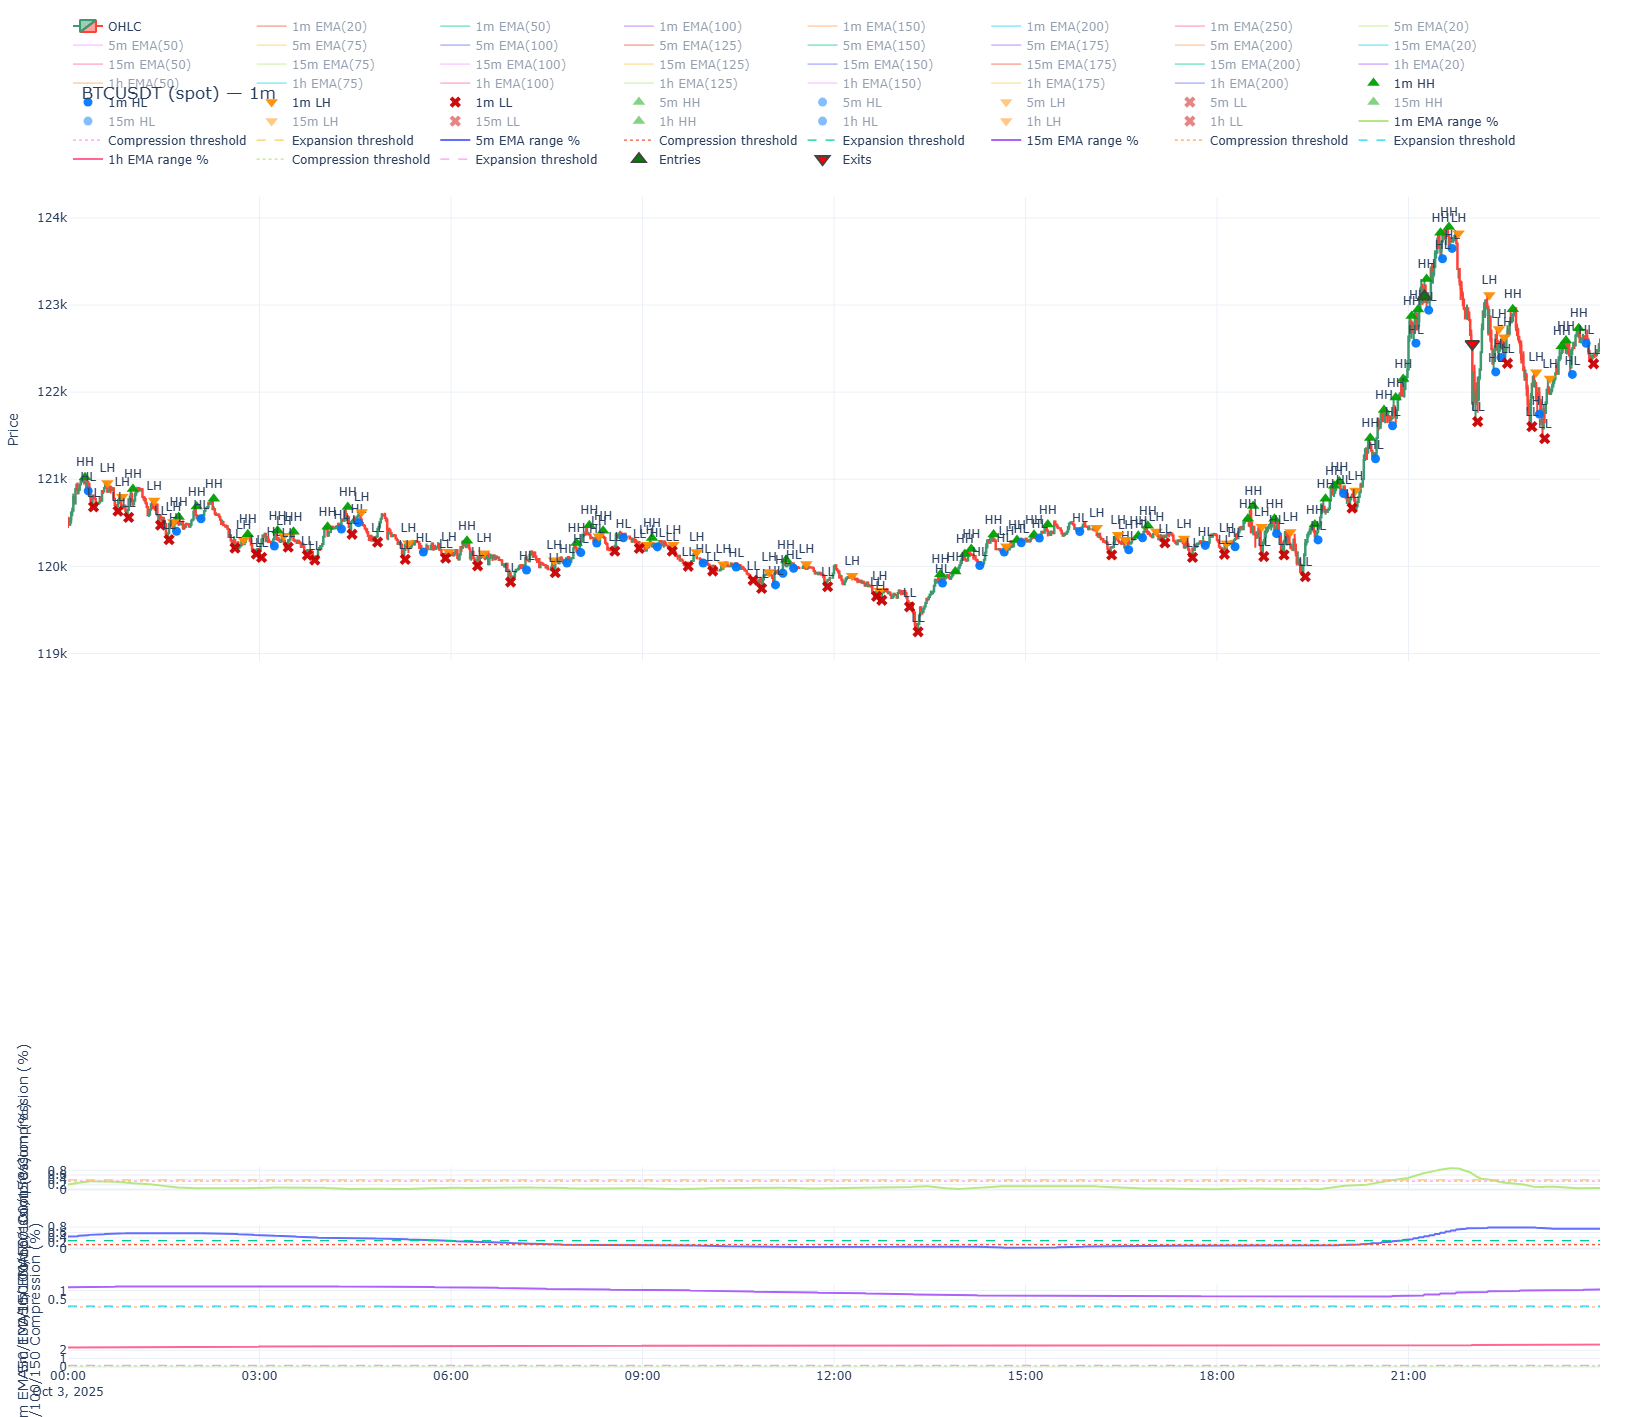

In [34]:
plot_simulation(
    df_raw=merged,
    symbol=symbol,
    interval="1m",
    market=market,
    trades=res.trades,
    ma_windows=[],
    indicators=plot_indicators,
    plot_cfg=PlotConfig(
        tz=tz,
        # date_from="2026-03-23",
        # date_to="2026-03-24",
        date_from="2025-10-03",
        date_to="2025-10-04",
        height=1400,
        width=1900,
    ),
)
